# Climate Change Attribution with FaIR

## Introduction

In this lab, we will explore the attribution of climate change to different climate drivers using FaIR. We will run a series of model experiments using the *single-forcing* modelling approach, in which one climate driver at a time is switched on. This approach allows us to attribute a certain amount of warming to each climate driver.

As a point of reference, our aim in this lab is to see if we can create a plot similar to Figure SPM.2 of the [IPCC Sixth Assessment Report Summary for Policy Makers](https://www.ipcc.ch/report/ar6/wg1/figures/summary-for-policymakers/figure-spm-2/).

As in the last lab, we will first focus on the historical time period. However, note that we are using radiative forcings derived using an older generation of historical and future scenarios, the Representative Concentration Pathways (RCPs), rather than the current Shared Socio-Economic Pathways (SSPs).

If you are using the JupyterHub, remember to:

`pip install fair==1.6.4`

First, let's import out packages:

In [2]:
# import packages
import fair
import numpy as np
from matplotlib import pyplot as plt
plt.style.use('seaborn-darkgrid')
plt.rcParams['figure.figsize'] = (16, 9)

In order to do these *single-forcing* experiments using FaIR, we will need to run in the **radiative forcing** mode, rather than the **emissions-driven mode** we used last week.

Let's use the RCP8.5 scenario experiment to compute the radiative forcings for each climate driver:

In [3]:
from fair.RCPs import rcp85

C85, F85, T85 = fair.forward.fair_scm(emissions=rcp85.Emissions.emissions)

Let's look at the `F85` output - first, check the shape:

In [ ]:
# check the shape
F85.shape

There are 736 rows, corresponding to the number of years (1765-2500), and 13 columns, corresponding the the components of the radiative forcing:

Index     | Species                                               
-----------|-----------
0         | CO<sub>2</sub>                                             
1         | CH<sub>4</sub>  
2         | N<sub>2</sub>O  
3         | All other well-mixed GHGs 
4         | Tropospheric O<sub>3</sub>   
5         | Stratospheric O<sub>3</sub>    
6         | Stratospheric water vapour from CH<sub>4</sub> oxidation   
7         | Contrails  
8         | Aerosols    
9         | Black carbon on snow  
10        | Land use change  
11        | Volcanic
12        | Solar

With the exception of volcanic and solar, all forcing outputs are calculated from the input historical emissions.

We will assess the contribution of each climate driver to the temperature anomaly using its *radiative forcing*.

Let's get started!

## Total Historical Warming

First, let's compute the total temperature anomaly in FaIR in **emissions-driven mode**, i.e., the historical warming as in the IPCC. We know from our last lab that FaIR did a pretty good job of simulating the historical temperature anomalies, so we can assume that the total observed warming is similar to what we get from FaIR.

The anomaly in the IPCC is calculated as the 2010-2019 average relative to the 1850-1900 average.

In [15]:
# define start and end years for historical period
yr_is = 85 #1850
yr_ie = 255 #2019

# years
year_hist = rcp85.Emissions.year[yr_is:yr_ie]

# Temperature Anomaly (2010-2019 relative to 1850-1900)
T85_hist = np.mean(T85[yr_ie-9:yr_ie]) - np.mean(T85[yr_is:yr_is+50])
print("The warming relative to pre-industrial in FaIR is ", np.round(T85_hist,2))

The warming relative to pre-industrial in FaIR is  1.14


Ok, great! This is the total warming. This is similar to what is shown in the IPCC Summary for Policy Makers. 

Let's check that we get a similar result when running in the **radiative forcing** mode, rather than **emissions-driven** mode.

Here, we will read in the radiative forcing using the `other_rf=` argument. We sum over all the individual radiative forcings to get the total.

In [253]:
# run the model using radiative forcing with emissions off
_,F85_rf,T85_rf = fair.forward.fair_scm(
    emissions=False,
    other_rf=np.sum(F85,axis=1),
    useMultigas=False)

Now, let's recalculate the temperature anomaly to see if we get a similar result (it should be quite similar given the radiative forcings are derived from the emissions):

In [1]:
# Temperature Anomaly (2010-2019 relative to 1850-1900)
#T85_hist_rf = 
#print("The warming relative to pre-industrial in FaIR is ", np.round(T85_hist_rf,2))

Pretty close. Good, let's move on to the single-forcing experiments.

## Single-Forcing Warming Contributions

Now, we want to see how much of this warming is due to different climate drivers. 

### Carbon Dioxide, CO$_2$

We will start with CO$_2$. To do this, we run the model as before, but we set the `other_rf=` argument to just the radiative forcing associated with CO$_2$:

In [255]:
# run the model using radiative forcing with emissions off
_,F85_co2,T85_co2 = fair.forward.fair_scm(
    emissions=False,
    other_rf=F85[:,0], #co2 only
    useMultigas=False)

Now, we can compute the temperature anomaly associated with CO$_2$ as we did above:

In [2]:
# Temperature Anomaly (2010-2019 relative to 1850-1900)
#T85_hist_co2 = 
#print("The warming relative to pre-industrial for CO2 only in FaIR is ", np.round(T85_hist_co2,2))

### Methane, CH$_4$

Let's repeat for methane (fill-in the code below):

In [6]:
# run the model using radiative forcing with emissions off
_,F85_ch4,T85_ch4 = fair.forward.fair_scm(
    emissions=False,
    other_rf= , #ch4 only
    useMultigas=False)

In [3]:
# Temperature Anomaly (2010-2019 relative to 1850-1900)
#T85_ch4_hist = 
#print("The warming relative to pre-industrial for CH4 in FaIR is ", np.round(T85_ch4_hist,2))

### Nitrous Oxide, N$_2$O

Fill-in the code below:

In [272]:
# run the model using radiative forcing with emissions off
_,F85_n2o,T85_n2o = fair.forward.fair_scm(
    emissions=False,
    other_rf=, #n2o only
    useMultigas=False)

In [4]:
# Temperature Anomaly (2010-2019 relative to 1850-1900)
#T85_n2o_hist = 
#print("The warming relative to pre-industrial for N2O in FaIR is ", np.round(T85_n2o_hist,2))

### All RF Components

Rather than doing each forcing at a time, let's create a loop to do them all in one go (fill-in the missing code below):

In [275]:
# run the model using radiative forcing with emissions off

# initialize two 2-D arrays for size (736,13)
F85_all = np.zeros((F85.shape[0],F85.shape[1]))
T85_all = np.zeros((F85.shape[0],F85.shape[1]))

# loop over all climate forcings
for i in range(F85.shape[1]):
    _,F,T = fair.forward.fair_scm(
        emissions=False,
        other_rf=,
        useMultigas=False)
    F85_all[:,i] = F
    T85_all[:,i] = T

## Attribution Time Series

As in the first figure or the IPCC AR6 Summary for Policy Makers, let's plot a time series of the historical temperature anomly when all forcings are included and when only natural (solar and volcanic) forcings are included. 

**Remember just to plot the time series for the historical time period**

No handles with labels found to put in legend.


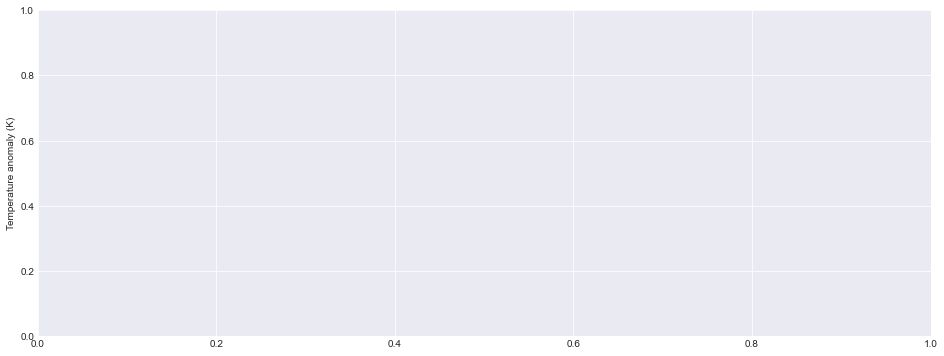

In [16]:
# plot time series
plt.figure(figsize=(16,6))

# plot time series for the "all forcing" case:
plt.plot(year_hist,np.sum(T85_all[yr_is:yr_ie,:],axis=1), label="All Forcings")

# plot time series for the "natural forcing" case:
#plt.plot(...,label="Natural Forcings")
plt.ylabel("Temperature anomaly (K)")
plt.legend()
plt.savefig("Fig1.png")

Now, let's compute the temperatue anomaly (2010-2019 relative to 1850-1900) associated with each climate forcing.

**Remember that T85_all is a 2-D array**

In [17]:
# Temperature Anomaly (2010-2019 relative to 1850-1900)
#T85_all_hist = 

Let's check that the individual warming components add up to the total that we computed above:

In [18]:
#print("The sum of all the warming contributions relative to pre-industrial in FaIR is ", np.round(np.sum(T85_all_hist),2))

Great! Now, let's plot each contribution in a bar plot:

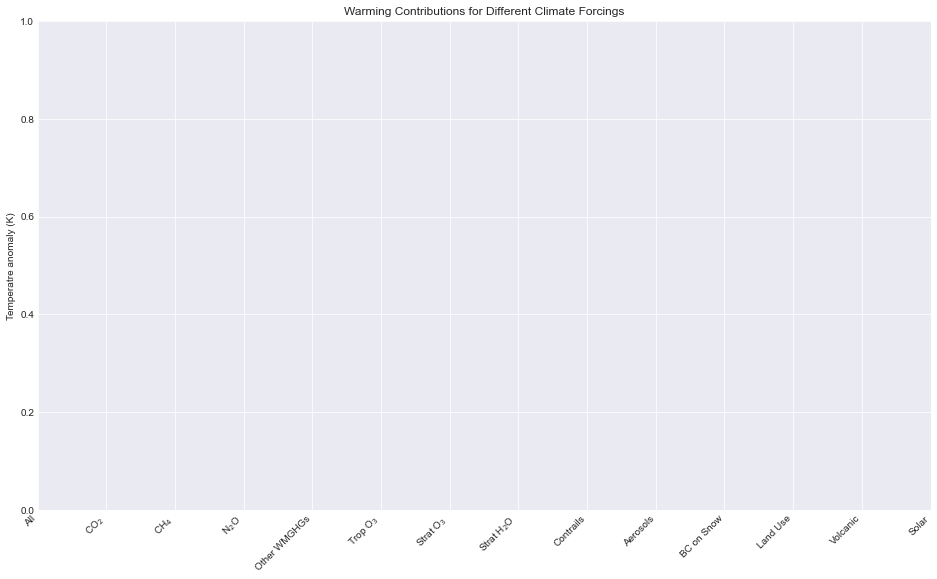

In [27]:
# first concatenate the total warming anomaly
T85_warming_contributions = np.hstack((T85_hist_rf,T85_all_hist))

# plot a bar plot of warming contributions
#plt.bar(np.arange(0,14),T85_warming_contributions)
plt.title("Warming Contributions for Different Climate Forcings")
plt.ylabel("Temperatre anomaly (K)")
plt.xticks(np.arange(0,14),["All","CO$_2$","CH$_4$","N$_2$O","Other WMGHGs","Trop O$_3$","Strat O$_3$","Strat H$_2$O","Contrails","Aerosols",
            "BC on Snow","Land Use","Volcanic","Solar"],rotation=45, ha="right")

plt.savefig("Fig2.png")

Finally, let's try to reproduce [panels (a) and (b) of SPM.2] (https://www.ipcc.ch/report/ar6/wg1/downloads/report/IPCC_AR6_WGI_SPM_final.pdf) 

**(excluding the internal variability bar)**.

In [21]:
# total human
#total_human = 
#print(total_human)

In [22]:
# total wmghg
#total_wmghg = 
#print(total_wmghg)

In [23]:
# total other human
#total_other = 
#print(total_other)

In [24]:
# total natural
#total_volc_sol = 
#print(total_volc_sol)

In [299]:
# stack them together for the plot
IPCC_warming_contributions = np.hstack((total_human,total_wmghg,total_other,total_volc_sol))

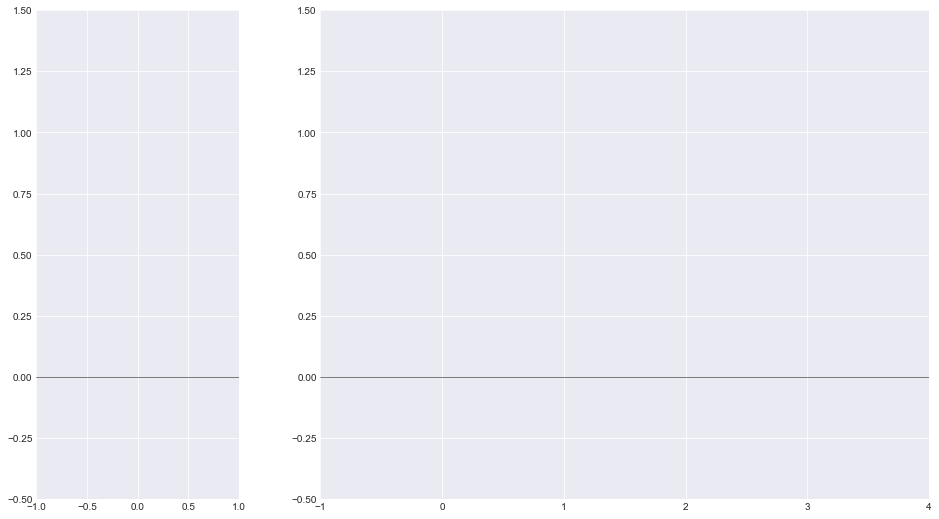

In [25]:
# plot a bar plot of warming contributions
f, (a0, a1) = plt.subplots(1, 2, gridspec_kw={'width_ratios': [1, 3]})

a0.bar(np.arange(0,1),T85_hist_rf,width=0.5,color="gray")
a0.set_xlim(-1,1)
a0.set_ylim(-1,2)
a0.set_yticks([-1,-0.5,0,0.5,1,1.5,2])
a0.axhline(0,color='k',linewidth=0.5)
a1.bar(np.arange(0,4),IPCC_warming_contributions,width=0.5,color=['crimson','crimson','cadetblue','crimson'])
a1.set_xlim(-1,4)
a1.set_ylim(-1,2)
a1.set_yticks([-1,-0.5,0,0.5,1,1.5,2])
a1.axhline(0,color='k',linewidth=0.5)
plt.savefig("Fig3.png")

How do the results from FaIR compare to the IPCC AR6 SPM.2 figure? 

## Please check your results for your Figure 3 against your Figure 2! 

Do they match up? Make sure you are slicing your arrays correctly to create Figure 3. Recall that Python is a zero-indexed language (things start counting from zero), and is also *left inclusive, right exclusive* you are when specifying a range of values. 